In [1]:
import numpy as np
import math
import time
import matplotlib.pyplot as plt

In [2]:
R, N_PMT, r, a, Y = 2.0, 40, 0.1, 0.5, 10000
E = 1.0
N = round(Y * E)
position = (0.0, 0.0, 0.0)

In [3]:
indices = np.arange(N_PMT)
z = R * (1 - 2 * (indices + 0.5) / N_PMT)
phi_pmt = indices * np.pi * (3 - np.sqrt(5))
rho = np.sqrt(R**2 - z**2)
pmt_positions = np.column_stack((rho * np.cos(phi_pmt), rho * np.sin(phi_pmt), z))
pmt_list = [tuple(map(float, row)) for row in pmt_positions]
print('Число фотонов:', N, '| ФЭУ:', len(pmt_positions))

Число фотонов: 10000 | ФЭУ: 40


In [ ]:
def directions_loop(n, seed=42):
    "Список направлений по одному фотону за итерацию "
    rng = np.random.default_rng(seed)
    result = []
    phis = rng.uniform(0, 2*np.pi, n)
    cos_thetas = rng.uniform(-1, 1, n)
    for i in range(n):
        c = float(cos_thetas[i])
        s = math.sqrt(1 - c*c)
        ph = float(phis[i])
        result.append((s*math.cos(ph), s*math.sin(ph), c))
    return result

In [5]:
def directions_numpy(n, seed=42):
    rng = np.random.default_rng(seed)
    phis = rng.uniform(0, 2*np.pi, n)
    cos_thetas = rng.uniform(-1, 1, n)
    sin_thetas = np.sqrt(1 - cos_thetas**2)
    return np.column_stack((
        sin_thetas*np.cos(phis),
        sin_thetas*np.sin(phis),
        cos_thetas
    ))

In [6]:
dirs_l = directions_loop(N)
dirs_np = directions_numpy(N)
assert isinstance(dirs_l, list)
assert dirs_np.shape == (N,3)
assert np.allclose(np.asarray(dirs_l), dirs_np)
assert np.allclose(np.linalg.norm(dirs_np, axis=1), 1)
print('Генерация: результаты совпадают, формы', len(dirs_l), dirs_np.shape)

Генерация: результаты совпадают, формы 10000 (10000, 3)


In [7]:
def propagate_loop(directions, position, radius=R):
    px, py, pz = position
    p2 = px*px + py*py + pz*pz
    if p2 >= radius**2:
        raise ValueError('Источник должен находиться внутри сферы')
    points = []
    for dx, dy, dz in directions:
        b = px*dx + py*dy + pz*dz
        t = -b + math.sqrt(b*b + radius*radius - p2)
        points.append((px+t*dx, py+t*dy, pz+t*dz))
    return points

In [8]:
def propagate_numpy(directions, position, radius=R):
    pos = np.asarray(position, dtype=float)
    p2 = pos @ pos
    if p2 >= radius**2:
        raise ValueError('Источник должен находиться внутри сферы')
    b = directions @ pos
    t = -b + np.sqrt(b*b + radius*radius - p2)
    return pos[None, :] + directions*t[:, None]

In [9]:
points_l = propagate_loop(dirs_l, position)
points_np = propagate_numpy(dirs_np, position)
assert np.allclose(np.asarray(points_l), points_np)
assert np.allclose(np.linalg.norm(points_np, axis=1), R)
print('Распространение: результаты совпадают')

Распространение: результаты совпадают


In [10]:
def hits_loop(points, pmt_centers=pmt_list, radius=r):
    counts = [0] * len(pmt_centers)
    r2 = radius**2
    for x,y,z in points:
        nearest, nearest_d2 = -1, float('inf')
        for j, (cx,cy,cz) in enumerate(pmt_centers):
            d2 = (x-cx)**2 + (y-cy)**2 + (z-cz)**2
            if d2 < nearest_d2:
                nearest, nearest_d2 = j, d2
        if nearest_d2 <= r2:
            counts[nearest] += 1
    return counts

In [11]:
def hits_numpy(points, pmt_centers=pmt_positions, radius=r):
    d2 = np.sum((points[:, None, :] - pmt_centers[None, :, :])**2, axis=2)
    nearest = np.argmin(d2, axis=1)
    accepted = d2[np.arange(len(points)), nearest] <= radius**2
    return np.bincount(nearest[accepted], minlength=len(pmt_centers))

In [12]:
hits_l = hits_loop(points_l)
hits_np = hits_numpy(points_np)
assert np.array_equal(hits_l, hits_np)
print('Число попавших фотонов:', sum(hits_l))
print('Попадания по всем ФЭУ совпадают:', np.array_equal(hits_l, hits_np))

Число попавших фотонов: 259
Попадания по всем ФЭУ совпадают: True


In [13]:
def photoelectrons_loop(counts, efficiency=a, seed=123):
    rng = np.random.default_rng(seed)
    return [int(rng.poisson(efficiency * count)) for count in counts]

In [14]:
def photoelectrons_numpy(counts, efficiency=a, seed=123):
    rng = np.random.default_rng(seed)
    return rng.poisson(efficiency * np.asarray(counts))

In [15]:
pe_l = photoelectrons_loop(hits_l)
pe_np = photoelectrons_numpy(hits_np)

In [ ]:
assert len(pe_l) == len(pe_np) == N_PMT
assert all(n >= 0 for n in pe_l) and np.all(pe_np >= 0)
print('Заряд (цикл):', sum(pe_l), '| заряд (NumPy):', np.sum(pe_np))
print('Ожидаемый средний заряд при заданных попаданиях:', a * np.sum(hits_np))

Заряд (цикл): 111 | заряд (NumPy): 111
Ожидаемый средний заряд при заданных попаданиях: 129.5


In [ ]:
# Оценка выигрыш во времени от использования numpy по сравнению с итерацией по отдельным фотонам
def benchmark(fn, repeats=5):
    fn()  # прогрев
    results = []
    for _ in range(repeats):
        start = time.perf_counter()
        fn()
        results.append(time.perf_counter() - start)
    return float(np.median(results))

steps = [
    ('Генерация', lambda: directions_loop(N), lambda: directions_numpy(N)),
    ('Распространение', lambda: propagate_loop(dirs_l, position), lambda: propagate_numpy(dirs_np, position)),
    ('Попадания в ФЭУ', lambda: hits_loop(points_l), lambda: hits_numpy(points_np)),
    ('Фотоэлектроны', lambda: photoelectrons_loop(hits_l), lambda: photoelectrons_numpy(hits_np)),
]
benchmarks = []
for name, slow, fast in steps:
    t_loop = benchmark(slow)
    t_numpy = benchmark(fast)
    benchmarks.append((name, t_loop, t_numpy, t_loop/t_numpy))
    print(f'{name:18} цикл={t_loop*1000:9.3f} мс | NumPy={t_numpy*1000:9.3f} мс | ускорение={t_loop/t_numpy:6.2f}x')

Генерация          цикл=   14.259 мс | NumPy=    0.756 мс | ускорение= 18.85x
Распространение    цикл=    5.902 мс | NumPy=    0.418 мс | ускорение= 14.13x
Попадания в ФЭУ    цикл=  356.788 мс | NumPy=   31.223 мс | ускорение= 11.43x
Фотоэлектроны      цикл=    0.078 мс | NumPy=    0.058 мс | ускорение=  1.35x


In [20]:
def event_loop():
    directions = directions_loop(N)
    points = propagate_loop(directions, position)
    counts = hits_loop(points)
    return sum(photoelectrons_loop(counts))

In [21]:
def event_numpy():
    directions = directions_numpy(N)
    points = propagate_numpy(directions, position)
    counts = hits_numpy(points)
    return int(np.sum(photoelectrons_numpy(counts)))

In [22]:
t_total_loop = benchmark(event_loop, repeats=3)
t_total_numpy = benchmark(event_numpy, repeats=3)
speedup = t_total_loop / t_total_numpy
print(f'Полное событие: цикл {t_total_loop:.4f} c, NumPy {t_total_numpy:.4f} c')
print(f'Ускорение: {speedup:.2f}x')

Полное событие: цикл 0.4015 c, NumPy 0.0295 c
Ускорение: 13.63x


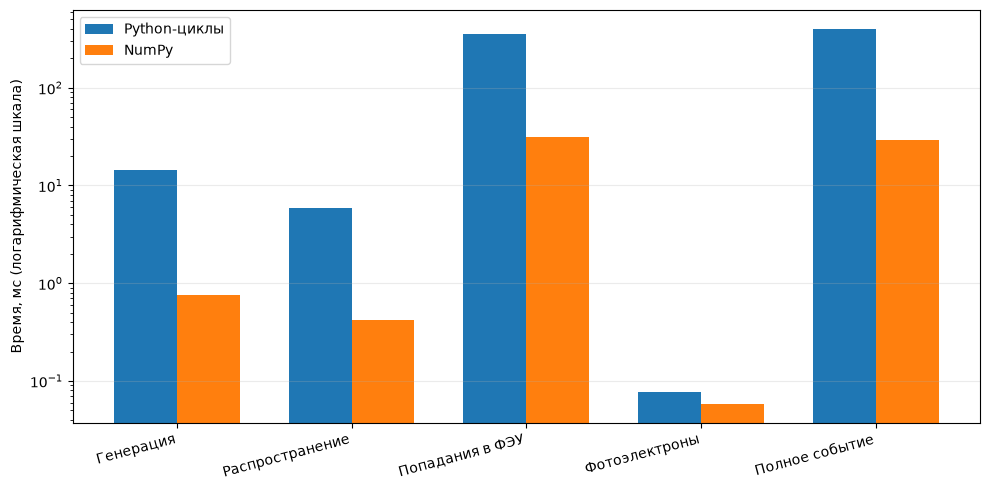

In [23]:
names = [x[0] for x in benchmarks] + ['Полное событие']
slow_ms = [x[1]*1000 for x in benchmarks] + [t_total_loop*1000]
fast_ms = [x[2]*1000 for x in benchmarks] + [t_total_numpy*1000]
fig, ax = plt.subplots(figsize=(10,5))
x = np.arange(len(names))
ax.bar(x - 0.18, slow_ms, width=0.36, label='Python-циклы')
ax.bar(x + 0.18, fast_ms, width=0.36, label='NumPy')
ax.set_yscale('log')
ax.set_ylabel('Время, мс (логарифмическая шкала)')
ax.set_xticks(x, names, rotation=15, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

в любых способах генерации numpy обгоняет обычные циклы многократно, в особенности в случае генерации